# Tutorial

This tutorial notebook serves as a guide on how to use the package's main functionalities:
1. [Loading files and data structures](##1.-Loading-files-and-data-structures)
2. [Distance functions for dynamic models and heatmaps](##2.-Distance-functions-for-dynamic-models-and-heatmaps)
3. [Clustering algorithms](##3.-Clustering-algorithms)
4. [Dimensionality reduction algorithms](##-4.-Dimensionality-reduction-algorithms)

## Background on the Scifate data

Before working with the package, it is first helpful to have a basic understanding on the Scifate data, in which this package works on. Below is a summarized overview of the data and what information each of the files contain. For more information, refer to the [original paper](https://www.nature.com/articles/s41587-020-0480-9).

<b><i>Scifate data</i></b>
- Sci-fate is a high-throughput sequencing method designed to track transcriptional dynamics of cells (i.e cells which are newly synthesized within a specific window of time) as compared to traditional methods which only observe a "static snapshot" of the cell at a specific moment
- By labelling new mRNA with the 4sU molecule, "old" and "new" genetic activity in the cell are tracked over a 10-hour response

<br>

| File name | Description | Information | Dataset size (gene x cell) | 
| --------- | ----------- | ------------ | ------------ |
matrix.mtx.gz | Gene expression matrix | Dataset showing the activity levels of all genes across all individual cells | (43750, 7404) |
4sU.Binom.ntr.mtx.gz | New to Total Ratio matrix | The proportion of a gene's total expression that is "new” | (43750, 7404) |
barcodes.tsv.gz | Barcodes + metadata | Unique molecular tags used to identify cells | (7404, 1) |
features.tsv.gz | Features + metadata | Metadata on genes measured | (43750, 5) |
trajectories_sci.csv | Trajectory table | Trajectory of how cells are connected to each other across time points | (949, 7) |


<break>

---

## 0. Load Dependencies

To start, install the package by following the instructions in the `README.md` file.

Once installation is complete, run the cell below to load the package and get started with the tutorial!

In [1]:
# load dependency
import hdadata as hda

<br>

## 1. Loading files and data structures

This section demonstrates methods on creating an HDAData object, inspecting and retrieving the object data.

<i> Jump to: 

- [Load the Sci-fate dataset and create an HDAData object](###-Load-files-and-Create-HDAData-Object)
- [Inspect the object and its contents](###-Inspect-object)
- [View the underlying data matrix](###-View-matrix)
- [Slice the data](###-Slicing)
- [Retrieve gene expression values](###-Get-gene-expression)

</i>

### Load files and Create HDAData Object

Every function in this package operates on an `HDAData` object, so the first step is always to create one.

An `HDAData` object has the following attributes:

| Attribute | Description |
|---|---|
| `X` | Gene expression matrix |
| `obs` | Cell barcodes |
| `var` | Gene features |
| `layers` | Additional matrices (e.g. new-to-total RNA ratio) |
| `similarities` | Stored similarity matrices |
| `clusters` | Stored clustering labels |
| `embeddings` | Stored dimensionality reduction embeddings |
| `trajectories` | Trajectory table |

<br>

> This design is inspired by [AnnData](https://anndata.readthedocs.io/en/latest/tutorials/notebooks/getting-started.html)

`load_scifate()` is a convenience function that loads the Sci-fate data from the `/data` folder and returns a ready-to-use `HDAData` object in one step:

In [2]:
hdata = hda.load_scifate()

### Inspect object

Printing the `HDAData` object gives a quick summary of its contents (dimensions, available layers, etc.).

In [3]:
print(hdata)

HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna']
  similarities: []
  clusters: []
  embeddings: []
  trajectories: Yes


Each of the object's tabular attributes is stored as a `pandas.DataFrame`, so you can use familiar pandas methods to explore them.

To inspect the **cell barcode** data, use `hdata.obs`. Here we call `.head()` to preview the first five rows:

In [4]:
hdata.obs.head()

,name,cell,time,barcode
cell_name,,,,
A549.4h.AAAAACTCTCTCAA,A549.4h.AAAAACTCTCTCAA,A549,4h,AAAAACTCTCTCAA
A549.6h.AAAAAAGAAGTTCA,A549.6h.AAAAAAGAAGTTCA,A549,6h,AAAAAAGAAGTTCA
A549.8h.AAAAACGGAGAATA,A549.8h.AAAAACGGAGAATA,A549,8h,AAAAACGGAGAATA
A549.4h.AAAACGATCCTGGA,A549.4h.AAAACGATCCTGGA,A549,4h,AAAACGATCCTGGA
A549.6h.AAAAACTGAATTCC,A549.6h.AAAAACTGAATTCC,A549,6h,AAAAACTGAATTCC


To inspect the **gene feature** data, use `hdata.var`:

In [5]:
hdata.var.head()

,gene_id,gene_symbol,feature_type,annotation,length
gene_symbol,,,,,
MTOR-AS1,ENSG00000225602,MTOR-AS1,Gene Expression,Exonic (h.ens90),705
ANGPTL7,ENSG00000171819,ANGPTL7,Gene Expression,Exonic (h.ens90),2238
RPL39P6,ENSG00000238173,RPL39P6,Gene Expression,Exonic (h.ens90),150
SNORA59A,ENSG00000239149,SNORA59A,Gene Expression,Exonic (h.ens90),152
AADACL4,ENSG00000204518,AADACL4,Gene Expression,Exonic (h.ens90),1575


To inspect the **trajectory** data, use `hdata.trajectories`:

In [6]:
hdata.trajectories.head()

,0h,2h,4h,6h,8h,10h
1,A549.0h.CCGGGCGCTCGACG,A549.2h.GCTGGCGGTTATTG,A549.4h.CTACTGGTCCAGTC,A549.6h.GACAATGCTCGCAA,A549.8h.AAAAAACTACCGAC,A549.10h.AATGCAACCGGATC
2,A549.0h.CGTCCTTAGTTCAA,A549.2h.AGCTACTCCGCCAA,A549.4h.GTTACTCTTAGCGG,A549.6h.AGTCTCGTAGGCTT,A549.8h.AAAAACGGAGAATA,A549.10h.CTCCTGGATCAGGC
3,A549.0h.GGGATAGCTGCTAC,A549.2h.CAGGCGATCATTAC,A549.4h.CAAAGACGAGGTTG,A549.6h.CCTAGATCAGTCAT,A549.8h.AAAATAGAATAGCC,A549.10h.GGCTGACCTGGAAT
4,A549.0h.CGACATAATCTCGC,A549.2h.GCTAACTGGTAGAT,A549.4h.GTTCTCTCTCATCC,A549.6h.GACTGCTCATATGC,A549.8h.AAAATTCTACGCCA,A549.10h.CCGCCTCGGTCAAT
5,A549.0h.CTGTAGGTCTATGG,A549.2h.ATCTATCTAGGTTC,A549.4h.GCGGATCCTACCTC,A549.6h.GCGAGGCCTCCATT,A549.8h.AAACAACTACCGAC,A549.10h.ACCTGGTCCAGGAG


### View matrix

View the underlying data matrix (e.g. `X` or `ntr`) in different formats, limited to the first *n* rows and columns. By default, `.show()` displays the gene expression matrix (`X`) unless another matrix is specified.

Supported formats (`mode`):
1. `"coo"` 
    - Coordinate List format (row, column, value)
    - Returns `None` if the selected subset contains only zero entries
2. `"dense"`
    - A numeric matrix as a NumPy array
3. `"label"`
    - A labelled `pandas.DataFrame`, with gene names as rows and cell names as columns

In [7]:
# Inspect the first 5 rows and columns of the gene expression matrix (X)

# Option 1: COO
print(f'First 5 rows and columns of X in COO format: ')
print(hdata.show(matrix=hdata.X, n_rows=5, n_cols=5, mode="coo"))
print(f'-'*20)

# Option 2: Dense
print(f'\nFirst 5 rows and columns of X in Dense format: ')
print(hdata.show(matrix=hdata.X, n_rows=5, n_cols=5, mode="dense"))
print(f'-'*20)

# Option 3: Labelled 
print(f'\nFirst 5 rows and columns of X in Label format: ')
df_X = hdata.show(matrix=hdata.X, n_rows=5, n_cols=5, mode="label")
df_X


First 5 rows and columns of X in COO format: 
None
--------------------

First 5 rows and columns of X in Dense format: 
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
--------------------

First 5 rows and columns of X in Label format: 


cell_name,A549.4h.AAAAACTCTCTCAA,A549.6h.AAAAAAGAAGTTCA,A549.8h.AAAAACGGAGAATA,A549.4h.AAAACGATCCTGGA,A549.6h.AAAAACTGAATTCC
gene_symbol,,,,,
MTOR-AS1,0,0,0,0,0
ANGPTL7,0,0,0,0,0
RPL39P6,0,0,0,0,0
SNORA59A,0,0,0,0,0
AADACL4,0,0,0,0,0


### Slicing

For downstream tasks, we'll often need a subset of the data. We can slice an `HDAData` object by gene/cell **name** or by **index**. The syntax follows standard Python list slicing conventions, with genes as the first axis and cells as the second: `hdata[genes, cells]`.

Indexing patters are such:

```python
hdata['Gene1', 'Cell1']                      # Single gene and cell
hdata[['Gene1', 'Gene2'], :]                 # Multiple genes, all cells
hdata[:, ['Cell1', 'Cell2']]                 # All genes, specific cells
hdata['Gene1':'Gene10', 'Cell1':'Cell5']     # Slice by name
hdata[:5, ['Cell1', 'Cell2']]                # Slice by gene index and cell names
hdata[['Gene1', 'Gene2'], :5]                # Slice by gene name and cell index
hdata[10:20, 30:40]                          # Integer indexing
```

A few examples using these patterns:

In [8]:
# Example 1: Get cell using cell name

cell1 = hdata[:, "A549.10h.GAGCTGAGACTCTA"]
cell1.show(n_rows=5, mode="label")

cell_name,A549.10h.GAGCTGAGACTCTA
gene_symbol,
MTOR-AS1,1
ANGPTL7,0
RPL39P6,0
SNORA59A,0
AADACL4,0


In [9]:
# Example 2: Get gene using gene name

gene1 = hdata["MTOR-AS1", :]
gene1.show(n_cols=5, mode="label")

cell_name,A549.4h.AAAAACTCTCTCAA,A549.6h.AAAAAAGAAGTTCA,A549.8h.AAAAACGGAGAATA,A549.4h.AAAACGATCCTGGA,A549.6h.AAAAACTGAATTCC
gene_symbol,,,,,
MTOR-AS1,0,0,0,0,0


In [10]:
# Example 3: Subset 10 rows and 10 columns from X

subset = hdata[10:20, 30:40]
subset.show(n_rows=5, n_cols=5, mode="label")

cell_name,A549.4h.AAAATCCGTCGCCA,A549.0h.AAAAACGCGTATCG,A549.2h.AAAACAGCAGTATC,A549.0h.AAAACATTATTACC,A549.10h.AAAACGTATTGAGA
gene_symbol,,,,,
PRAMEF12,0,0,0,0,0
PRAMEF20,0,0,0,0,0
AL354712.1,0,0,0,0,0
RPL7P11,0,0,0,0,0
AL357552.1,0,0,0,0,0


### Get gene expression

Retrieve gene expression values directly through the following functions:

1. `.get_expression()`
    - returns the expression value for a **specific gene in a specific cell**. Accepts either names or indices.

2. `.get_gene_expression()` 
    - returns the expression values for a **gene across all cells**. Accepts either a name or an index.

In [11]:
# Example 1: get gene expression using gene name and cell name

print(hdata.get_expression("MTOR-AS1", "A549.10h.GAGCTGAGACTCTA"))

1


In [12]:
# Example 2: get gene expression using gene index and cell index

print(hdata.get_expression(0, 0))

0


In [13]:
# Example 3: get gene expression using gene name

print(hdata.get_gene_expression("MTOR-AS1"))

A549.4h.AAAAACTCTCTCAA     0
A549.6h.AAAAAAGAAGTTCA     0
A549.8h.AAAAACGGAGAATA     0
A549.4h.AAAACGATCCTGGA     0
A549.6h.AAAAACTGAATTCC     0
                          ..
A549.8h.CGCCAACGGAACGC     0
A549.6h.CGCCTCTAGTCAAG     0
A549.6h.CGCCGCTCATATGC     0
A549.2h.CGCCCTTCCAAGAA     0
A549.10h.CGCCTTGGAGCTCA    0
Name: MTOR-AS1, Length: 7404, dtype: int64


In [14]:
# Example 4: get gene expression using gene index

print(hdata.get_gene_expression(1))

A549.4h.AAAAACTCTCTCAA     0
A549.6h.AAAAAAGAAGTTCA     0
A549.8h.AAAAACGGAGAATA     0
A549.4h.AAAACGATCCTGGA     0
A549.6h.AAAAACTGAATTCC     0
                          ..
A549.8h.CGCCAACGGAACGC     0
A549.6h.CGCCTCTAGTCAAG     0
A549.6h.CGCCGCTCATATGC     0
A549.2h.CGCCCTTCCAAGAA     0
A549.10h.CGCCTTGGAGCTCA    0
Name: ANGPTL7, Length: 7404, dtype: int64


---

## 2. Distance functions for dynamic models and heatmaps

This section demonstrates the use of distance functions and heatmaps through an example biological use case on the Scifate dataset.

<b>Biological Use Case: </b>

<b>Identify dynamically regulated transcriptional programs during cortisol stress response using Highly Variable Genes (HVGs) </b>

The following similarities are explored:

| Analysis | Biological Interpretation |
| --------- | ----------- | 
| Gene-gene similarity | Co-regulated dynamic stress-response genes |
| Cell-cell similarity | Cells with similar transcriptional stress states |
| Trajectory similarity | Similar temporal response paths |

<br>

<i> Jump to: 

- [Highly Variable Genes (HVG)](###-Highly-Variable-Genes-(HVG))
- [Gene-gene similarity](###-Gene-gene-similarity)
- [Cell-cell similarity](###-Cell-cell-similarity)
- [Highly Dynamic Trajectories (HDT)](###-Highly-Dynamic-Trajectories-(HDT))
- [Trajectory-trajectory similarity](###-Trajectory-trajectory-similarity)

</i>

### Highly Variable Genes (HVG)

Since single-cell matrices are highly sparse, using all genes directly for analysis often produces unstable correlations. To obtain an informative subset from the sparse matrix, we can identify the Highly Variable Genes (HVGs).

In this package, HVGs are identified using the NTR matrix because NTR captures active transcriptional dynamics, making it suitable for studying temporal stress responses. For each gene, the variance of its NTR values across all cells is computed. Genes with higher variance indicate more active transcriptional changes across cells, such as initiating stress response.

For a gene $g_i$, the variance across all cells is computed as:

$$
\mathbf{Var}(g_i) =
\frac{1}{N}\sum_{j=1}^{N}(NTR_{ij}-\mu_i)^2
$$

where:
- $NTR_{ij}$ is the NTR value of gene $i$ and cell $j$
- $N$ is the total number of cells
- $\mu_i$ is the mean NTR of gene $i$

Genes are then ranked by variance in decreasing order, and the top *n* genes are selected as HVGs.

<br>

> This idea is inspired by: [scanpy.experimental.pp.highly_variable_genes](https://scanpy.readthedocs.io/en/stable/generated/scanpy.experimental.pp.highly_variable_genes.html#scanpy.experimental.pp.highly_variable_genes) , 
[seurat highly variable genes](https://satijalab.org/seurat/articles/pbmc3k_tutorial.html)

In [15]:
# Get top 10 HVGs

top_10_genes = hdata.get_highly_variable_genes(n=10)
print(f'Top 10 gene names: {top_10_genes}')

Top 10 gene names: ['YOD1', 'SGK1', 'PARD6B', 'SMAD7', 'KLF6', 'KLF10', 'CEBPD', 'PLK2', 'ADM', 'GRPEL2']


Since we only want to analyze the top 10 HVGs, next we initialize a temporary subset of the `hdata` object containing just these 10 genes and all cells. Slicing also carries over the associated metadata (`obs`, `var`, and `layers`), which are subsetted alongside the matrix, so they only contain values for the 10 HVGs and all cells.

This keeps everything we need for downstream analysis in one place, so we can work directly with `subset_top10` instead of repeatedly filtering the full `hdata` object.

In [16]:
# Initialize a temporary subset object for the top 10 HVGs (to be used later)

subset_top10 = hdata[top_10_genes, :]       # 10 genes, 7404 cells

### Gene-gene similarity 

Now that we've identified the top 10 HVGs, we can compare whether these genes exhibit similar behaviour during the stress response. As an initial approach, we compare them directly using their raw NTR values. For instance, each gene is represented by a vector of its NTR values across all cells:


$$
\mathbf{g}_i =
[NTR_{i1}, NTR_{i2}, ..., NTR_{iN}]
$$

where:
- $NTR_{ij}$ is the NTR value of HVG $i$ and cell $j$
- $N$ is the total number of cells

The distance between two gene vectors is then computed using one of the following metrics:
- `correlation`, or
- `cosine`

From these distances, we compute a similarity score for each pair of genes, giving us a similarity matrix:

$$
S = 
\begin{matrix}
S_{11} & S_{12} & \cdots & S_{1n} \\
S_{21} & S_{22} & \cdots & S_{2n} \\
\vdots & \vdots & \ddots & \vdots \\
S_{n1} & S_{n2} & \cdots & S_{nn}
\end{matrix}
$$

where:
- $S_{ij}$ is similarity score of gene $i$ and gene $j$
- $n$ is the total number of HGV genes
- $S_{ii}$ = 1 (a gene is always perfectly similar to itself)

The function `.compute_similarity()` retrieves the vectors, computes the distances, then converts them into a similarity matrix. The resulting matrix is stored back into the original object, at `HDAData.similarities`.

The `id` parameter lets you assign a custom name for the resulting similarity matrix to avoid overwritting an existing matrix.

In [17]:
# Compute gene-gene similarity of top 10 HVGs using raw NTR

hdata.compute_similarity(
    data=subset_top10,                 # use the temporary subset as data
    key="ntr",                         
    kind="gene",                       
    method="correlation",              # metric
    id="corr_ntr_gene"                 # name id
)

Similarity "corr_ntr_gene" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna']
  similarities: ['corr_ntr_gene']
  clusters: []
  embeddings: []
  trajectories: Yes

To inspect gene-gene similarity dataframe, retrieve it from `.similarities` attribute with the right id.

In [18]:
sim_1 = hdata.similarities["corr_ntr_gene"]        # use the same id
sim_1

,YOD1,SGK1,PARD6B,SMAD7,KLF6,KLF10,CEBPD,PLK2,ADM,GRPEL2
YOD1,1.000000,0.100134,0.062567,0.091714,0.169095,0.065951,0.067229,0.136405,0.122610,0.127108
SGK1,0.100134,1.000000,0.036117,0.083644,0.083344,0.053835,0.125137,0.057928,0.049556,0.077367
PARD6B,0.062567,0.036117,1.000000,0.054674,0.085799,0.064356,0.076837,0.049415,0.087599,0.095415
SMAD7,0.091714,0.083644,0.054674,1.000000,0.110295,0.089687,0.027949,0.090426,0.104398,0.093695
KLF6,0.169095,0.083344,0.085799,0.110295,1.000000,0.114303,0.077222,0.138555,0.169065,0.109297
KLF10,0.065951,0.053835,0.064356,0.089687,0.114303,1.000000,0.029685,0.106823,0.099798,0.073749
CEBPD,0.067229,0.125137,0.076837,0.027949,0.077222,0.029685,1.000000,0.006355,0.020968,0.037757
PLK2,0.136405,0.057928,0.049415,0.090426,0.138555,0.106823,0.006355,1.000000,0.192419,0.094190
ADM,0.122610,0.049556,0.087599,0.104398,0.169065,0.099798,0.020968,0.192419,1.000000,0.098048
GRPEL2,0.127108,0.077367,0.095415,0.093695,0.109297,0.073749,0.037757,0.094190,0.098048,1.000000


To visualize the gene-gene similarity heatmap, use the function `hda.visualize.heatmap()`. Pass in the pre-computed similarity matrix `sim_1` from the previous step, and set `show_cluster=True` if you wish to show the clustered dendograms above the heatmap. Otherwise, set `show_cluster=False`.

In [19]:
# Plot clustered heatmap to visualize the similarity

hda.visualize.heatmap(
    sim=sim_1,                  
    type="gene", 
    show_cluster=True,          
    title="Gene-gene correlation similarity with raw NTR"
)

The gene-gene similarity heatmap above is still fairly weak to interpret, since it's derived from a sparse matrix (10 HVG × 7404 cells). To get a finer, more interpretable heatmap, the next sections show how to work with a less sparse matrix instead (e.g 10 HVG × 12 cells).

### Cell-cell similarity

Next, we analyze cell-cell similarity to study cells with similar transcriptional states during the cortisol stress response, based on the HVGs we identified earlier.

To obtain a representative subset of cells, we randomly select a number of cells from each trajectory timepoint using the cell barcode metadata (`obs`).

Unlike the gene-gene analysis, which uses NTR values to study transcriptional dynamics, cell-cell similarity can be computed using gene expression values, since these better reflect the current transcriptional state of a cell.

A cell vector can be defined as:

$$
\mathbf{c}_j =
[X_{1j}, X_{2j}, \ldots, X_{nj}]
$$

where:
- $X_{ij}$ is the gene expression value of HVG $i$ and cell $j$
- $n$ is the total number of HVGs

If gene expression values `X` are used, the cell vectors are normalized using a shifted logarithm (log-transformation of normalized counts) to stabilize variance across high and low expression values. Normalization is omitted if NTR is used to build the cell vector instead, since NTR values are already considered normalized.

The normalized vector $X'_{ij}$  is computed as:

$$
X'_{ij}
=
\log\left(
\frac{X_{ij}}
{\mathrm{library\_size}_j}
\times s
+1
\right)
$$

where:
- $library\_size{_j}$ is the total sum of count for all features for cell $j$
- $s$ is the scaling factor (e.g: 0.0001) to bring values to a comparable magnitude
- +1 is added to avoid log(0) for unexpressed genes

<br>

> This idea is inspired by: [scanpy.pp.log1p](https://scanpy.readthedocs.io/en/stable/generated/scanpy.pp.log1p.html#scanpy.pp.log1p)

<br>

The normalized cell vectors are then used to compute cell-cell similarity, following the same procedure described in the gene-gene similarity section.

The function `.get_timepoint_cells()` randomly gets *n* number of cells for each timepoint (**0h, 2h, 4h, 6h, 8h, 10h**) from the cell barcodes table `obs`.

In [20]:
# Get two random cells for each timepoint 

cells_12 = hdata.get_timepoint_cells(n=2)    # 2 cells x 6 timepoints = 12 cells      
cells_12

['A549.0h.CGTTACGGCAACCA',
 'A549.0h.ACGCCTCGATGGAG',
 'A549.2h.GAGTCCTACGGCAA',
 'A549.2h.CCTTCCTAAGCGGT',
 'A549.4h.AGTTGTCGAGGTAT',
 'A549.4h.GACGATGAGTTCTC',
 'A549.6h.ATATTCCTTACCAA',
 'A549.6h.GCCTAATCGAACTC',
 'A549.8h.AAGGCGGCAGAGGA',
 'A549.8h.CCGAGACCGTAGCA',
 'A549.10h.GATTATCGTATCAA',
 'A549.10h.GAAAGACCTGGAAT']

In [21]:
# Initialize a temporary subset object for the selected cells (to be used later)

subset_hvg_cell = hdata[top_10_genes, cells_12]        # 10 genes, 12 cells

In [22]:
# Compute cell-cell similarity of the selected cells using gene expression values 

hdata.compute_similarity(
    data=subset_hvg_cell,               # use the temporary subset as data
    key="X",                            
    kind="cell",                        
    method="correlation",
    id="corr_X_cell"
)

sim_2 = hdata.similarities["corr_X_cell"]

Similarity "corr_X_cell" stored! 



In [23]:
# Plot clustered heatmap to visualize the similarity

hda.visualize.heatmap(
    sim=sim_2, 
    type="cell", 
    show_cluster=True,
    title="Cell-cell correlation similarity"
)

Now with a finer matrix (10 HVG × 12 cells), we observe a more interpretable resulting heatmap.

### Highly Dynamic Trajectories (HDT)

As we have looked at gene-gene and cell-cell similarity, it is also possible to investigate trajectory-trajectory similarity. 

In order to identify a representative subset of trajectories to analyze, we can adopt a similar concept to the HVG, by retrieving the top Highly Dynamic Trajectories (HDT). 

Given that we have information about our HVG, for each trajectory in the trajectory table, a matrix of shape (HVG $\times$ timepoints) is assembled using the NTR values of the HVG genes and cells at that timepoint, in order to capture the transcriptional dynamics of a trajectory over time. The matrix is then flattened row-wise into a single trajectory vector:

$$
\mathbf{traj}_i =
[NTR_{g1,0h}, NTR_{g1,2h}, ...,NTR_{g2,0h}, NTR_{g2,2h}, ...]
$$

where:
- $NTR_{g,t}$ is the NTR value of HVG $g$ and cell $j$ at timepoint $t$

We can then calculate the variance of each trajectory such that:

$$
\mathbf{Var}(traj_i) =
\frac{1}{M}\sum_{k=1}^{M}(v_{ik}-\bar{v})^2
$$

where:
- $v_{ik}$ is $k$-th element of the flattened vector
- $M$ is the total number of HVG $\times$ timepoints
- $\bar{v}$ is the mean of $traj_{i}$ 

Trajectories are then ranked by variance in decreasing order, and the top *n* trajectories are selected as HDTs.

In [24]:
# Get top 20 HDTs

top_20_traj = subset_top10.get_highly_dynamic_trajectories(n=20)
print(f'Top 20 trajectories:\n{top_20_traj}')

Top 20 trajectories:
[884, 194, 157, 797, 926, 160, 252, 709, 349, 866, 860, 29, 298, 170, 68, 531, 56, 617, 441, 381]


### Trajectory-trajectory similarity

To investigate the similar temporal response path among trajectories during cortisol stress response, we can compute the trajectory-trajectory similarity using the selected HDTs with their respective gene expression values.

Here, `trajectory_id=top_20_traj` restricts the computation to the trajectories we just selected, instead of using all trajectories in the trajectory table.

In [25]:
# Compute trajectory-trajectory similarity of HDTs using gene expression values

hdata.compute_similarity(
    data=subset_top10,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj,          # use only selected trajectories
    method="correlation",
    id="corr_X_traj"
)

sim_3 = hdata.similarities["corr_X_traj"]

Similarity "corr_X_traj" stored! 



In [26]:
# Plot heatmap to visualize the similarity

hda.visualize.heatmap(
    sim=sim_3, 
    type="trajectories", 
    show_cluster=True,
    title="Trajectory-trajectory correlation similarity"
)

---

## 3. Clustering algorithms

As we've seen how we can identify similar genes, cells or trajectories by visualizing their similarity through heatmaps, let's now take this a step further by applying **clustering** to understand why certain trajectories group together. This section continues the biological use case and builds on the results from [Section 2](##-2.-Distance-functions-for-dynamic-models-and-heatmaps). The clustering examples below focus mainly on **trajectories**. 

<i> Jump to: 

- [KMeans](###-KMeans)
- [Hierarchical Clustering](###-Hierarchical-Clustering)
- [Graph-based Clustering](###-Graph-based-clustering)

</i>

### KMeans

KMeans is the first clustering algorithm we'll explore. It partitions data into clusters based on linear separability. The function `.find_kmeans_k()` is an aid that plots the Within Cluster Sum of Squares (WCSS) <i>(also known as inertia)</i> against different numbers of $k$, to visually assist in finding a possible choice for $k$. Using the Elbow method, we can identify the point of diminishing returns and pick a suitable $k$.

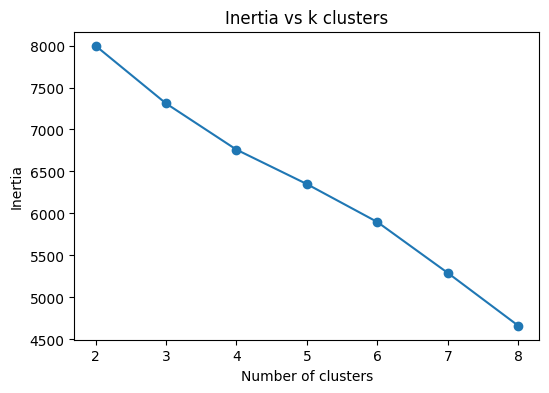

In [27]:
# Plot inertia vs k to find the optimal k using Elbow method

hdata.find_kmeans_k(
    data=subset_top10,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj,
    max_clusters=8                          # maximum number of clusters to form
)

Based on the resulting plot, $k$=4 might be a reasonable choice in this case.

Now, we can run KMeans on the top 20 Highly Dynamic Trajectories (HDTs) `top_20_traj` that we found earlier. Note that, unlike other clustering methods in this package, KMeans does not operate on a pre-computed similarity/distance matrix, rather it works directly in the raw feature space, computing its own internal Euclidean distances. So instead of passing a similarity matrix, `.cluster_kmeans()` needs the raw vectors, which it builds internally from the parameters we provide.

The resulting cluster labels are stored as a `pandas.Series` back into the original object, at `HDAData.clusters`.

In [28]:
# Cluster the top 20 trajectories (HDT) using KMeans

hdata.cluster_kmeans(
        data=subset_top10,                   # use the same subset with top 10 HVGs
        key="X",
        kind="trajectory",
        trajectory_id=top_20_traj,           # use only selected trajectories
        k=4,                                 # k clusters
        id="c1_kmeans"    
    )

Cluster "c1_kmeans" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna']
  similarities: ['corr_ntr_gene', 'corr_X_cell', 'corr_X_traj']
  clusters: ['c1_kmeans']
  embeddings: []
  trajectories: Yes

In [29]:
# Inspect the KMeans results to see which trajectory belongs to which cluster

c1_kmeans = hdata.clusters["c1_kmeans"]
c1_kmeans

traj_884    0
traj_194    3
traj_157    2
traj_797    2
traj_926    0
traj_160    3
traj_252    1
traj_709    2
traj_349    3
traj_866    2
traj_860    0
traj_29     1
traj_298    1
traj_170    3
traj_68     0
traj_531    3
traj_56     1
traj_617    1
traj_441    3
traj_381    3
Name: c1_kmeans, dtype: int32

With the clustering results in hand, we can examine *why* certain trajectories are grouped together. For example, by visualizing how a **specific gene** is regulated over time across the trajectories in each cluster.

The function `hda.visualize.line()` produces the following line plots:
- One subplot per cluster, showing gene expression values plotted against trajectory timepoints. The thick dotted line represents the cluster mean, while individual lines represent each trajectory in that cluster.
- A final subplot on the right, overlaying all cluster means for comparison.

<br>

Recall that we used the top 10 HVGs for the trajectory clustering.

```python
Top 10 HVGs: ['YOD1', 'SGK1', 'PARD6B', 'SMAD7', 'KLF6', 'KLF10', 'CEBPD', 'PLK2', 'ADM', 'GRPEL2']
```

As an example, let's visualize how the gene `YOD1` is regulated over time across all trajectories in each cluster, to see whether they share a coherent pattern.

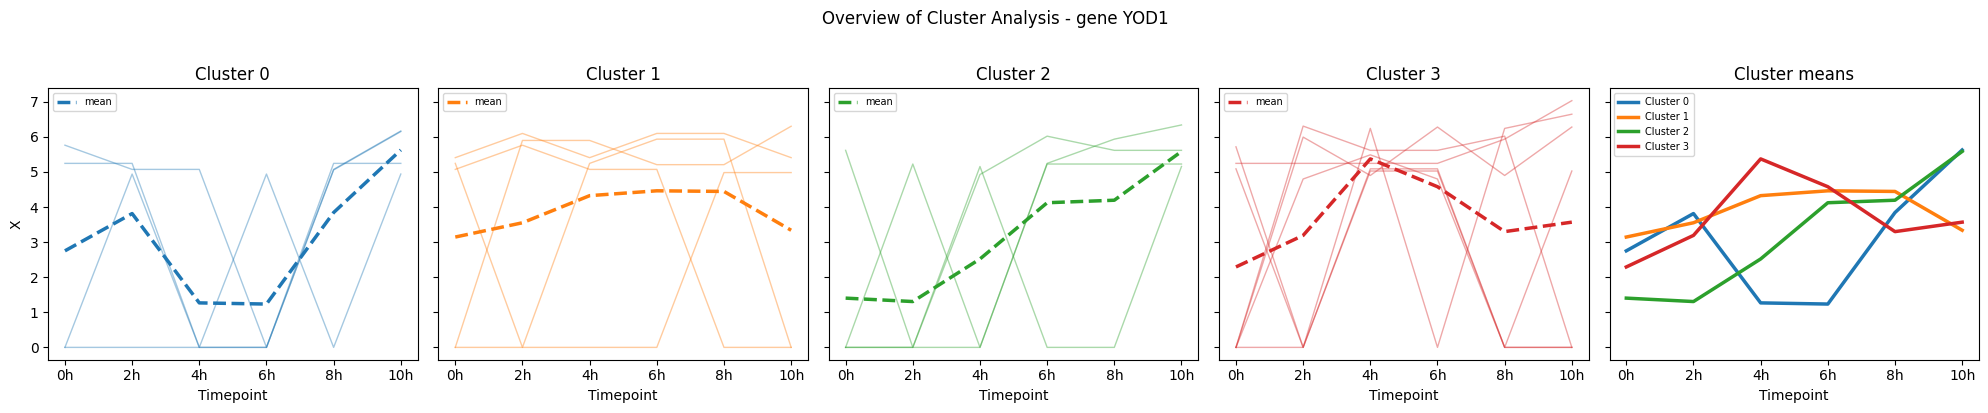

In [30]:
# Visualize gene YOD1 in trajectories cluster and the cluster mean

hda.visualize.line(
    data=subset_top10,
    cluster=c1_kmeans,                  # clustering result
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj,
    gene_sym="YOD1"                     # specify gene using gene symbol
)

Alternatively, `hda.visualize.heatmap_per_cluster()` plots a **per-cluster heatmap** of mean gene expression for each gene across trajectories, against trajectory timepoint. This gives an overview of the transcriptional program and shared behaviour within each cluster.

In [31]:
# Visualize per-cluster heatmap

hda.visualize.heatmap_per_cluster(
    data=subset_top10,
    cluster=c1_kmeans,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj
)

### Hierarchical Clustering

The second clustering algorithm we'll explore is hierarchical clustering, or more specifically **Agglomerative Clustering**, which is a bottom-up clustering approach. 

Since hierarchical clustering can work directly on a pre-computed similarity/distance matrix, we can reuse the trajectory correlation similarity matrix `sim_3` obtained earlier to run hierarchical clustering through the function `.cluster_hierarchical()`. 

Recall the [trajectory-trajectory correlation similarity heatmap](###-Trajectory-trajectory-similarity) from Section 2, the dendograms above the heatmap is already a form of Agglomerative clustering. We can now choose to form clusters either by setting $t$ threshold distance to "cut" the dendogram horizontally, or by setting a fixed $k$ number of clusters.

In [32]:
# Cluster the top 20 trajectories (HDT) using Hierarchical Clustering - Agglomerative 

hdata.cluster_hierarchical(
        sim=sim_3,                                 
        kind="trajectory",
        k=4,                           # k clusters
        id="c2_hier"
    )

c2_hier = hdata.clusters["c2_hier"]

Cluster "c2_hier" stored! 



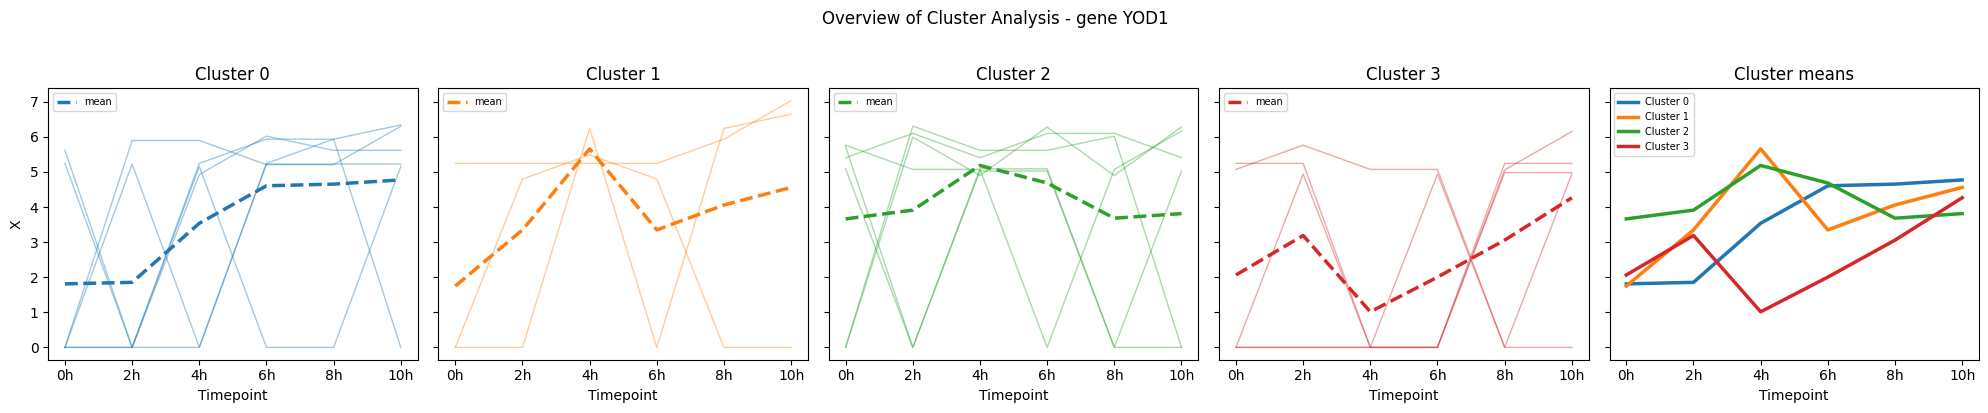

In [33]:
# Visualize gene YOD1 in trajectories cluster and the cluster mean

hda.visualize.line(
    data=subset_top10,
    cluster=c2_hier,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj,
    gene_sym="YOD1"
)

In [34]:
# Visualize per-cluster heatmap

hda.visualize.heatmap_per_cluster(
    data=subset_top10,
    cluster=c2_hier,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj
)

### Graph-based Clustering

The final clustering algorithm we'll explore is graph-based clustering, or more specifically **Spectral Clustering** in this case. 

Unlike KMeans, whose decision boundary is linear, spectral clustering groups data points based on their connectivity. This makes it well-suited for identifying clusters with complex or non-convex shapes that KMeans would struggle to separate. It works by converting the similarity matrix into a graph Laplacian matrix $L$, extracting its eigenvectors, and then applying KMeans in this lower-dimensional eigenspace.

As with hierarchical clustering, we can reuse of the trajectory correlation similarity matrix `sim_3` obtained earlier to run spectral clustering through the function `.cluster_spectral()`

In [35]:
# Cluster the top 20 trajectories (HDT) using Graph-based Clustering - Spectral

hdata.cluster_spectral(
        sim=sim_3,                                               
        kind="trajectory",
        k=4,
        id="c3_spec"
    )

c3_spec = hdata.clusters["c3_spec"]

Cluster "c3_spec" stored! 



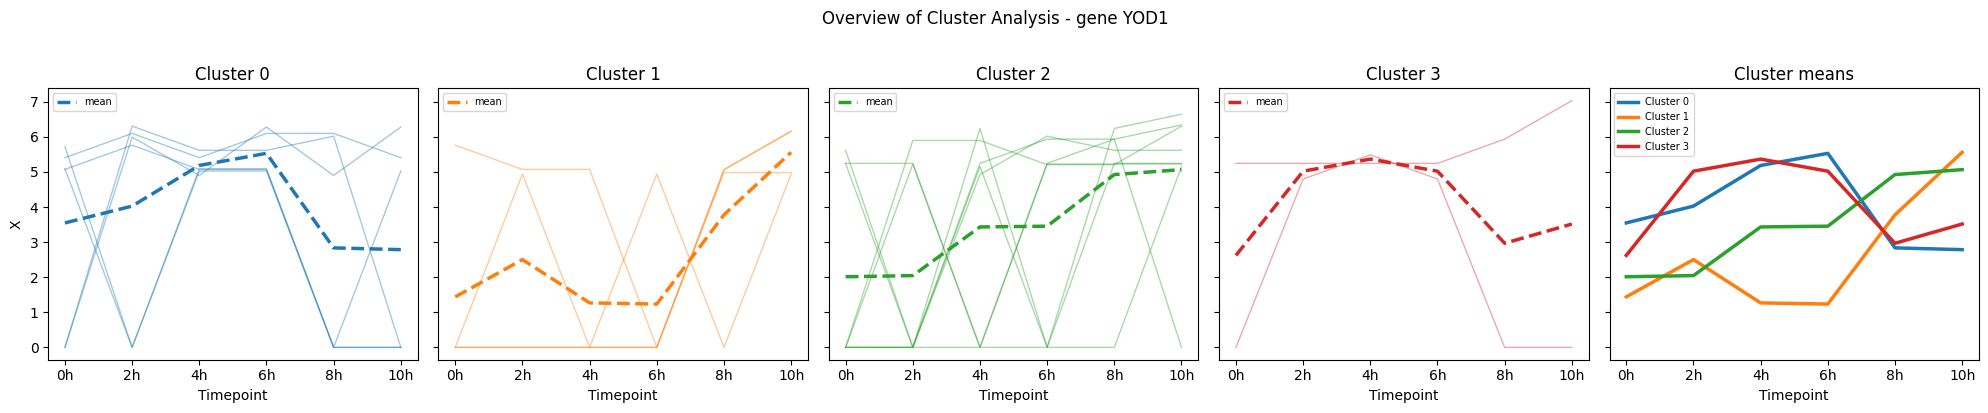

In [36]:
# Visualize gene YOD1 in trajectories cluster and the cluster mean

hda.visualize.line(
    data=subset_top10,
    cluster=c3_spec,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj,
    gene_sym="YOD1"
)

In [37]:
# Visualize per-cluster heatmap

hda.visualize.heatmap_per_cluster(
    data=subset_top10,
    cluster=c3_spec,
    key="X",
    kind="trajectory",
    trajectory_id=top_20_traj
)

<br>

Quick summary:

| Clustering Algorithm | Input |
| -- | -- | 
| KMeans | raw vectors |
| Hierarchical (Agglomerative) | similarity matrix |
| Graph-based (Spectral) | similarity matrix |

---

## 4. Dimensionality reduction algorithms

In the previous section, we've learned how to cluster the trajectories using various clustering algorithms. Due to the data's high-dimensional nature, visualizing the clusters directly would pose a challenge. Thus, this section explores dimensionality reduction algorithms such as PCA and UMAP to reduce the number of dimensions and visualize clusters in 2D space.

This section covers dimensionality reduction for both **cell** clusters and **trajectory** clusters.

<i> Jump to: 

- [Cell](#cellpart)
    - [Expression-distance clusters](###-1.-Expression-distance-clusters)
    - [PCA-based clusters](###-2.-PCA-based-clusters)
        - [Compare clusters with different PCs](####-2.1-Compare-PCA-based-clusters-with-different-PCs)
        - [Filtering UMAP plots](####-2.2-Filtering-UMAP-plots-on-PCA-based-clusters)
        - [Compare clusters on Total RNA vs New RNA](####-2.3-Compare-PCA-based-clusters-on-Total-RNA-vs-New-RNA)
- [Trajectories](#trajpart)
    - [Total RNA](###-Total-RNA)
        - [Concatenate first → PCA](#workflow11)
        - [PCA-first → Concatenate](#workflow12)
    - [New RNA](###-New-RNA)
        - [Concatenate first → PCA](#workflow21)
        - [PCA-first → Concatenate](#workflow22)
</i>

<a id="cellpart"></a>
### <b>Cell</b>

Starting with cell clusters, there are two defined methods to cluster cells, namely:
- Expression-distance clusters
- PCA-based clusters

For convenience, the examples throughout this section for Cells will be illustrated using a subset of 2000 HVGs and 600 cells, with Spectral Clustering.

In [38]:
# Create example with 2000 HVGs and 600 cells
top_hvg = hdata.get_highly_variable_genes(n=2000)
cells_600 = hdata.get_timepoint_cells(n=100)        # 100 x 6tp = 600 cells

# Initialize a temporary subset object
subset_cells_ = hdata[top_hvg, cells_600]  

### 1. Expression-distance clusters

The first method forms cell clusters using **expression-distance clustering**, which is the same approach used in [Section 3](##-3.-Clustering-algorithms), where clusters are formed via:

**gene $\times$ cell expression matrix → distance/similarity matrix → clustering**

In [ ]:
# Compute cell-cell similarity using gene expression values 
hdata.compute_similarity(
    data=subset_cells_,
    key="X",
    kind="cell",
    method="correlation",
    id="sim1"
)
sim1 = hdata.similarities["sim1"]

# Cluster the cells using Spectral Clustering
hdata.cluster_spectral(
        sim=sim1,                                 
        kind="cell",
        k=6,        
        id="cl1"
    )
cl1 = hdata.clusters["cl1"]


# # If KMeans used as clustering:
# # skip compute_similarity since sim is not required
# hdata.cluster_kmeans(
#         data=subset_cells_,
#         key="X",
#         kind="cell",
#         k=6,
#         id="cl1"
#     )
# cl1 = hdata.clusters["cl1"]

Similarity "sim1" stored! 

Cluster "cl1" stored! 



To visualize the cells clusters in 2D, use `reduce_UMAP()`. This applies **UMAP** to reduce the dimensionality and obtain 2D embeddings (UMAP1, UMAP2) coordinates used to plot each cell.

The resulting embeddings are stored back into the original object, at `HDAData.embeddings`.

In [40]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="X",
    kind="cell",
    id="em1"
)
em1 = hdata.embeddings["em1"]

# Inspect the embeddings
em1

UMAP embedding "em1" stored! 



(array([[ 3.5258996, 12.282222 ],
        [ 4.1020336, 13.288717 ],
        [ 3.9505951, 12.210209 ],
        ...,
        [ 2.8200285, 13.296019 ],
        [ 2.625153 , 12.43839  ],
        [ 2.7798405, 12.774854 ]], shape=(600, 2), dtype=float32),
 'UMAP1',
 'UMAP2')

Then, use `hda.visualize.scatter()` to plot the 2D scatter plot of the Spectral Clustering results. Each cluster is shown in a different colour. By default, `show_label=False` hides cell/trajectory names on the plot, set it to `True` if you want them displayed.

> Note: The UMAP plots might not be reproduced exactly the same since [UMAP embedding coordinates may differ](https://umap-learn.readthedocs.io/en/latest/reproducibility.html) slightly across different OS even with `random_state` set. Results also depend on library versions (Numba, NumPy) and OS-level floating-point behavior. However, cluster structure and Silhouette scores should remain consistent, only the visual layout (position, scale, orientation) of the embedding may vary.

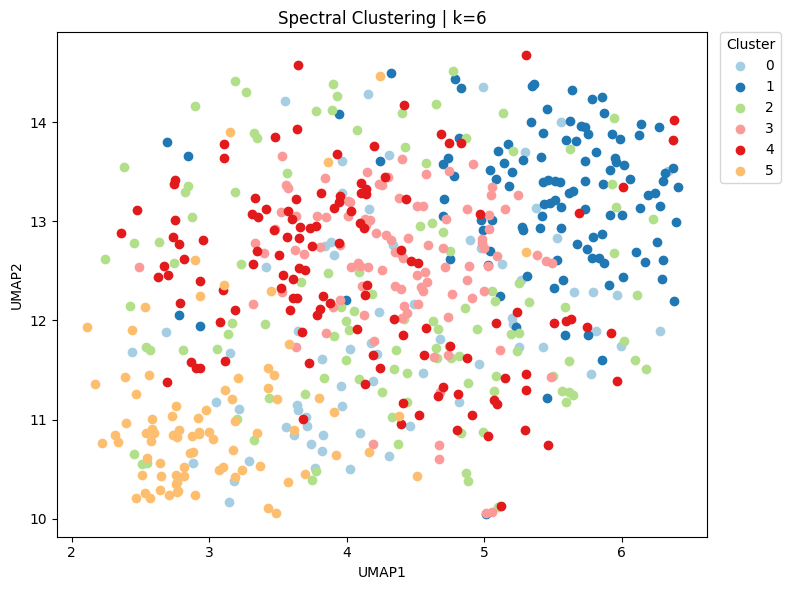

In [41]:
# Visualize 
hda.visualize.scatter(
    cluster=cl1,                            # cluster result
    embedding=em1,                          # embedding result
    title="Spectral Clustering | k=6",      
    show_label=False
)

Since we don't have ground-truth cluster labels, one way to evaluate cluster quality is the **Silhouette Score**, computed via `.calc_cl_silhouette_score()`. It's based on the distance between a point, its own cluster, and the nearest neighbouring cluster. Scores range from +1 to -1 (best to worst), scores near 0 indicate overlapping clusters.

If a precomputed similarity matrix is available (as with Spectral or Hierarchical Clustering), set `precomputed=True` and pass the relevant `sim` matrix. Otherwise, in the case for KMeans, which needs raw vectors to compute distances, set `precomputed=False` and pass the relevant parameters (`data`, `key`, `kind`) instead.

In [42]:
# Evaluate
score1 = hdata.calc_cl_silhouette_score(
        cl=cl1, 
        precomputed=True, 
        sim=sim1
        )

print(f'Silhouette score: {score1:.5f}')

Silhouette score: 0.00693


### 2. PCA-based clusters

The second method forms cell clusters using **PCA-based clustering**, where PCA is applied before clustering to obtain a reduced matrix (cell $\times$ PC matrix) as follows:

**gene $\times$ cell expression matrix → PCA → cell $\times$ PC matrix → distance/similarity matrix → clustering**

Principal Component Analysis (PCA) works directly on the raw feature space, finding the directions of maximum variance via eigendecomposition of the covariance matrix. Because of this, we need to provide raw information to `.compute_PCA()` rather than a similarity matrix. Set `kind="cell"` so that the function knows we're working on cells. The function builds the cell vectors from this raw information, then computes PCA using the given `n_pc` (number of principal components). The resulting reduced matrix (cell × PC matrix) is stored back into `HDAData.layers`.

Since the reduced PCA-based matrix captures the most important information beforehand, clustering results are generally expected to be <i>better</i> compared to expression-distance clustering.

In [43]:
# Example with 20 PCs

# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",         # use cell
    n_pc=20,             # number of PCs
    id="totalrna_pc20"
)

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell_totalrna_pc20"] 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_cell_totalrna_pc20']
  similarities: ['corr_ntr_gene', 'corr_X_cell', 'corr_X_traj', 'sim1']
  clusters: ['c1_kmeans', 'c2_hier', 'c3_spec', 'cl1']
  embeddings: ['em1']
  trajectories: Yes

<i> ! Be aware that the PCA matrix will be stored with the name starting with "pca_cell" or "pca_trajectory" depending on the type you're using, following by your defined `id`! Make sure that you use the correct key name for the next functions. </i>

Similarity "sim2" stored! 

Cluster "cl2" stored! 

UMAP embedding "em2" stored! 



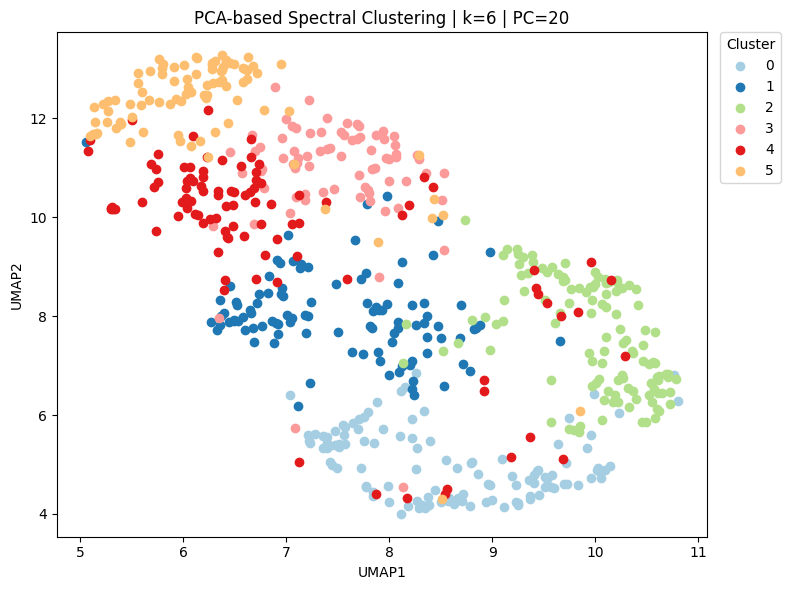

Silhouette score: 0.17002


In [ ]:
# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca_cell_totalrna_pc20",            # "pca_cell_<your set id in .compute_PCA>"
    kind="cell",
    method="correlation",
    id="sim2"
)
sim2 = hdata.similarities["sim2"]   

# Clustering
hdata.cluster_spectral(
    sim=sim2,
    kind="cell",
    k=6,
    id="cl2"
)
cl2 = hdata.clusters["cl2"]

# # If KMeans used as clustering:
# # skip compute_similarity since sim is not required
# hdata.cluster_kmeans(
#         data=subset_cells_,
#         key="pca_cell",
#         kind="cell",
#         k=6,
#         id="cl2"
#     )
# cl2 = hdata.clusters["cl2"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell_totalrna_pc20",          # "pca_cell_<your set id in .compute_PCA>"
    kind="cell",
    id="em2"
)
em2 = hdata.embeddings["em2"]

# Visualize 
hda.visualize.scatter(
    cluster=cl2,
    embedding=em2,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    show_label=False
)

# Evaluate
score2 = hdata.calc_cl_silhouette_score(
        cl=cl2, 
        precomputed=True, 
        sim=sim2
        )

print(f'Silhouette score: {score2:.5f}')

#### 2.1 Compare PCA-based clusters with different PCs

To see how sensitive the results are to the number of PCs used, repeat the same steps from the [subsection above](###-2.-PCA-based-clusters) with a different number of PCs, e.g. PC=5 or PC=50. Simply change `n_pc` to your desired value.

The image below compares Expression-distance clustering against PCA-based clustering at PC=5, PC=20, and PC=50.

![img1a](tutorial_images/img1a.jpg)

A few observations from the resulting UMAP plots above:
- PC=5: Cells form broad, coarse clusters, since distance is dominated by the top few signals. This may over-simplify the real substructure.
- PC=50: Clusters start to blur and overlap. The extra PCs introduce noise dimensions, diluting the real signal in the distance matrix.

A sweet spot is typically around PC=20 to PC=30, giving clusters that preserve the underlying structure without over-simplifying or adding noise.

<br>

#### 2.2 Filtering UMAP plots on PCA-based clusters

With interactive UMAP filtering, we can control how the plot is coloured based on the following criteria:

- One specific cluster
- One specific gene
- One specific timepoint
- One specific gene + One specific timepoint

The same scatter plot function, `hda.visualize.scatter()`, can be adjusted using different parameters to achieve each of these views.

The examples below apply UMAP filtering to the PCA-based cell clustering plot for PC=20.

To highlight only **one specific cluster** with colour, specify the cluster label in the `highlight` parameter.

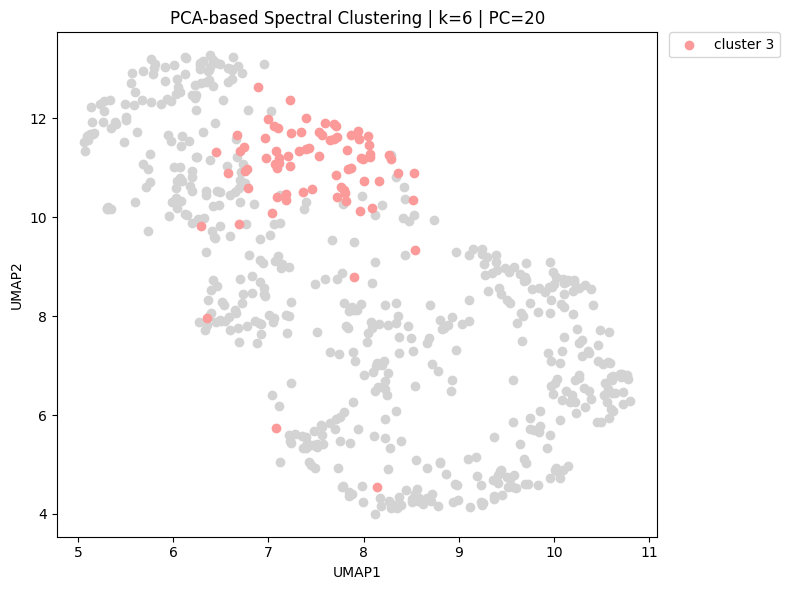

In [47]:
# One specific cluster

hda.visualize.scatter(
    cluster=cl2,
    embedding=em2, 
    highlight=3,            # Show only cluster number 3
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    )

To show the gene expression value of **one specific gene**, first use `.get_gene_expression(<gene name>)` to extract that gene's expression values, then pass the result to the `values` parameter, which colours the plot using a continuous colour bar.

Use `legend_label` to label what the plot is filtered on, for example, gene name or timepoint.

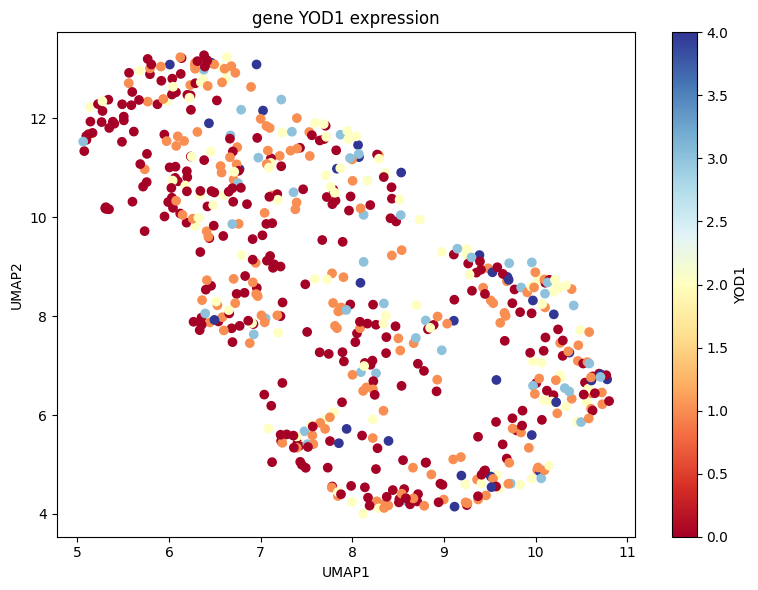

In [48]:
# One specific gene

g1 = subset_cells_.get_gene_expression('YOD1')     

hda.visualize.scatter(
    embedding=em2, 
    values=g1,                          # gene expression as values
    legend_label="YOD1",                # add gene name in legend
    title="gene YOD1 expression"
    )

To highlight only cells from **one specific timepoint**, first create a boolean mask for that timepoint using `obs`, then pass it to the `mask` parameter, which colours the plot using a discrete value.

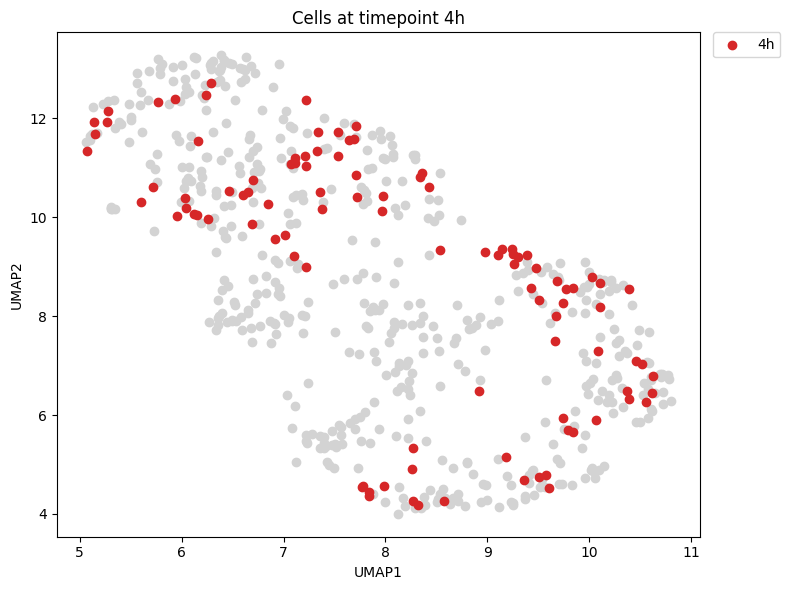

In [49]:
# One specific timepoint

time_mask = subset_cells_.obs["time"] == "4h"           

hda.visualize.scatter(
    embedding=em2, 
    mask=time_mask,                 # mask 
    legend_label="4h",
    title="Cells at timepoint 4h"
    )

To show only **one specific gene + one specific timepoint**, use both `values` and `mask` parameters together.

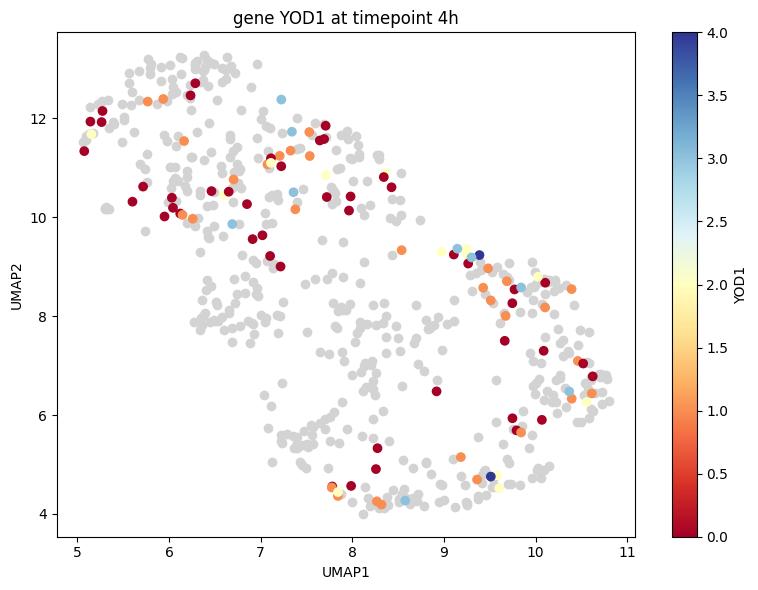

In [50]:
# One specific gene + One specific timepoint

hda.visualize.scatter(
    embedding=em2, 
    values=g1,                          # gene expression of "YOD1"
    mask=time_mask,                     # timepoint at 4h
    legend_label="YOD1",
    title="gene YOD1 at timepoint 4h"
    )

#### 2.3 Compare PCA-based clusters on Total RNA vs New RNA

**New RNA** represents the amount of newly synthesized RNA in a cell, estimated by multiplying the gene expression `X` (Total RNA) with NTR. It provides a measure of transcriptional activity at each timepoint during the 10-hour cortisol stress response.

So far, we've looked at PCA-based clusters using Total RNA. Now, let's compare PCA-based clusters on Total RNA vs. New RNA, to observe how clusters change once newly synthesized RNA is taken into account.

The process for PCA-based clustering remains the same:

**gene $\times$ cell expression matrix → PCA → cell $\times$ PC matrix → distance/similarity matrix → clustering**

The only difference is that the gene $\times$ cell expression matrix is now filled with New RNA values in instead of Total RNA `X` values.

New RNA is calculated automatically and stored in `HDAData.layers` when the object is initialized. So, to compute on New RNA values, we simply pass `"keys=new_rna"`.

The example below uses the same PC=20 as before, for easier comparison with the results from [subsection 2. PCA-based clusters](###-2.-PCA-based-clusters) above.

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell_newrna_pc20"] 

Similarity "sim3" stored! 

Cluster "cl3" stored! 

UMAP embedding "em3" stored! 



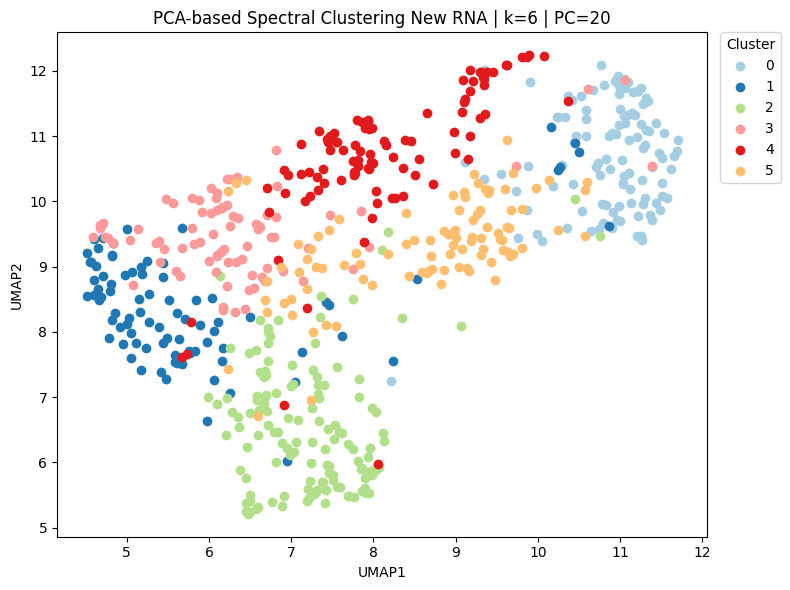

Silhouette score: 0.15001


In [51]:
# PCA for representation 
hdata.compute_PCA(
    data=subset_cells_,
    key="new_rna",           # use New RNA
    kind="cell",
    n_pc=20,                 # PC=20
    id="newrna_pc20"         
)

# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca_cell_newrna_pc20",             # "pca_cell_<your set id in .compute_PCA>"
    kind="cell",
    method="correlation",
    id="sim3"
)
sim3 = hdata.similarities["sim3"]   

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim3,
    kind="cell",
    k=6,
    id="cl3"
)
cl3 = hdata.clusters["cl3"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_cells_,
    key="pca_cell_newrna_pc20",              # "pca_cell_<your set id in .compute_PCA>"
    kind="cell",
    id = "em3"
)
em3= hdata.embeddings["em3"] 

# Visualize 
hda.visualize.scatter(
    cluster=cl3,
    embedding=em3,
    title="PCA-based Spectral Clustering New RNA | k=6 | PC=20",
    show_label=False
)

# Evaluate
score3 = hdata.calc_cl_silhouette_score(
        cl=cl3, 
        precomputed=True, 
        sim=sim3
        )

print(f'Silhouette score: {score3:.5f}')

For a quick comparison, the figure below shows PCA-based clustering results for Total RNA vs. New RNA, side by side, using 20 PCs. The left plot is the same one obtained earlier in [subsection 2. PCA-based clusters](###-2.-PCA-based-clusters).

![img1b](tutorial_images/img1b.jpg)

<br>

<a id="trajpart"></a>
### <b>Trajectories</b>

Now that we've covered the two methods for clustering cells, let's move on to **Trajectories**. As with cells, there are two defined workflows for clustering trajectories:
- Concatenate first → PCA
- PCA-first → Concatenate

Both workflows can be applied to either Total RNA or New RNA.

For convenience, the examples throughout this section for Trajectories will be illustrated using a subset of 2000 HVGs and 300 HDTs, with Spectral Clustering.

In [52]:
# Create example with 2000 HVGs
# top_hvg = hdata.get_highly_variable_genes(n=2000)

# Initialize a temporary subset object 
subset_traj_ = hdata[top_hvg, :]    # 2000 genes x allcells 
                                    # keep all cells available when using get_highly_dynamic_trajectories

# Get top 300 HDTs
top_traj = subset_traj_.get_highly_dynamic_trajectories(n=300)

### Total RNA

Let's start with the Total RNA examples.

<a id="workflow11"></a>
#### Workflow 1.1: Concatenate first → PCA

The first workflow concatenates ordered cell profiles by trajectory first before PCA. The steps are:

**trajectory $\times$ (gene*timepoint) matrix → PCA → trajectory $\times$ PC matrix → distance/similarity matrix → clustering**

As before, we start with `.compute_PCA()`, this time setting `kind="trajectory"` so the function knows we're working with trajectories. It builds the trajectory vectors from the trajectory × (gene×timepoint) matrix, then computes PCA using the given `n_pc` (number of principal components). The resulting reduced matrix (trajectory × PC matrix) is stored back into `HDAData.layers`.

In [53]:
# PCA on trajectory × (gene*timepoints) matrix
hdata.compute_PCA(
    data=subset_traj_,
    key="X",
    kind="trajectory",                      # use trajectory
    n_pc=20,
    trajectory_id=top_traj,
    id="total20_t"
)

PCA matrix trajectory x 20 PCs stored in HDAData.layers["pca_trajectory_total20_t"] 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_cell_totalrna_pc20', 'pca_cell_totalrna_pc5', 'pca_cell_totalrna_pc50', 'pca_cell_newrna_pc20', 'pca_trajectory_total20_t']
  similarities: ['corr_ntr_gene', 'corr_X_cell', 'corr_X_traj', 'sim1', 'sim2', 'sim_test5', 'sim_test50', 'sim3']
  clusters: ['c1_kmeans', 'c2_hier', 'c3_spec', 'cl1', 'cl2', 'cl_test5', 'cl_test50', 'cl3']
  embeddings: ['em1', 'em2', 'em_test5', 'em_test50', 'em3']
  trajectories: Yes

Similarity "sim4" stored! 

Cluster "cl4" stored! 

UMAP embedding "em4" stored! 



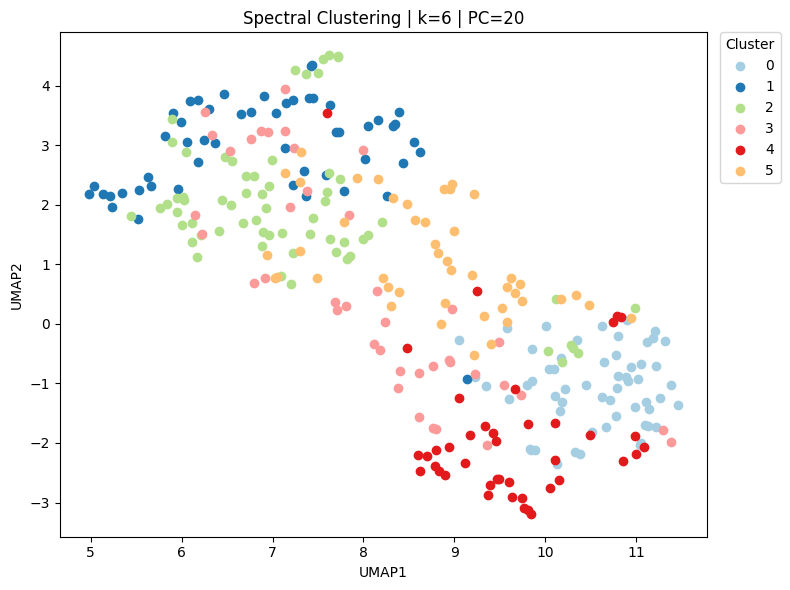

Silhouette score: 0.12489


In [54]:
# Compute distance/similarity in PC space
hdata.compute_similarity(
    data=subset_traj_,
    key="pca_trajectory_total20_t",              # "pca_trajectory_<your set id in .compute_PCA>"
    kind="trajectory",
    trajectory_id=top_traj,
    method="correlation",
    id="sim4"
)
sim4 = hdata.similarities["sim4"]

# Cluster in PC space
hdata.cluster_spectral(
        sim=sim4,                                               
        kind="trajectory",
        k=6,
        id="cl4"
    )
cl4 = hdata.clusters["cl4"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_traj_,
    key="pca_trajectory_total20_t",                # "pca_trajectory_<your set id in .compute_PCA>"
    kind="trajectory",
    trajectory_id=top_traj,
    id="em4"
)
em4 = hdata.embeddings["em4"]

# Visualize 
hda.visualize.scatter(
    cluster=cl4,
    embedding=em4,
    title="Spectral Clustering | k=6 | PC=20",
    show_label=False
)

# Evaluate
score4 = hdata.calc_cl_silhouette_score(
        cl=cl4, 
        precomputed=True, 
        sim=sim4
        )

print(f'Silhouette score: {score4:.5f}')

<a id="workflow12"></a>
#### Workflow 1.2: PCA first -> Concatenate

The second workflow applies PCA first on cell $\times$ gene matrix to get a cell $\times$ PC matrix. Then it concatenates ordered PC profiles by trajectories to build vectors before computing distance/similarity for clustering. The steps are:

**cell $\times$ gene matrix → PCA → cell $\times$ PC matrix → build trajectory vectors using PC scores → trajectory $\times$ PC*timepoints matrix → distance/similarity matrix → clustering**

As before, we start with `.compute_PCA()`, but this time set `kind="cell"` to compute PCA on cells. The resulting cell $\times$ PC matrix is stored back into `HDAData.layers`.

In [55]:
# PCA on cell x PC matrix
hdata.compute_PCA(
    data=subset_traj_,
    key="X",
    kind="cell",                    # use cell
    n_pc=20,
    id="total20_c"
)

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell_total20_c"] 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'new_rna', 'pca_cell_totalrna_pc20', 'pca_cell_totalrna_pc5', 'pca_cell_totalrna_pc50', 'pca_cell_newrna_pc20', 'pca_trajectory_total20_t', 'pca_cell_total20_c']
  similarities: ['corr_ntr_gene', 'corr_X_cell', 'corr_X_traj', 'sim1', 'sim2', 'sim_test5', 'sim_test50', 'sim3', 'sim4']
  clusters: ['c1_kmeans', 'c2_hier', 'c3_spec', 'cl1', 'cl2', 'cl_test5', 'cl_test50', 'cl3', 'cl4']
  embeddings: ['em1', 'em2', 'em_test5', 'em_test50', 'em3', 'em4']
  trajectories: Yes

Similarity "sim5" stored! 

Cluster "cl5" stored! 

UMAP embedding "em5" stored! 



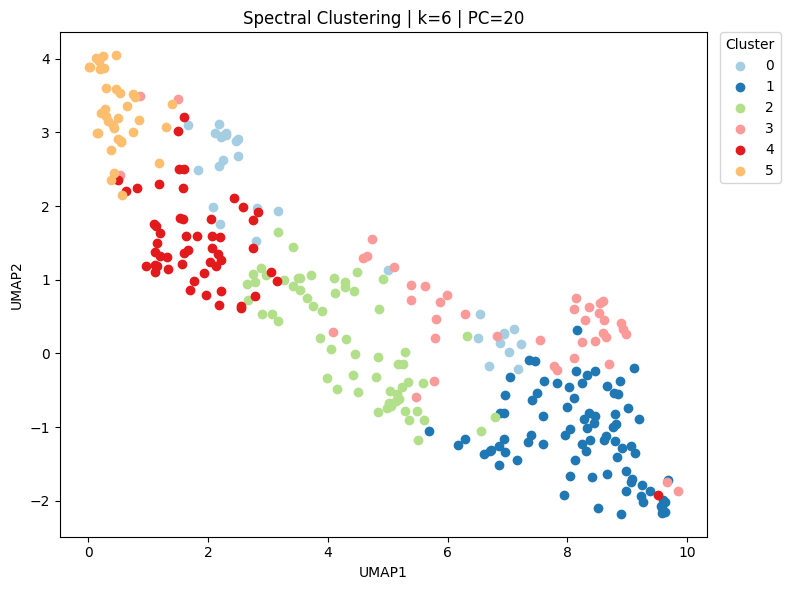

Silhouette score: 0.16869


In [56]:
# Compute distance/similarity in PC space
hdata.compute_similarity(
    data=subset_traj_,
    key="pca_cell_total20_c",                   # "pca_cell_<your set id in .compute_PCA>"
    kind="trajectory",
    trajectory_id=top_traj,
    method="correlation",
    id="sim5"
)
sim5 = hdata.similarities["sim5"]

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim5,
    kind="trajectory",
    k=6,
    id="cl5"
)
cl5 = hdata.clusters["cl5"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_traj_,  
    key="pca_cell_total20_c",                   # "pca_cell_<your set id in .compute_PCA>"
    kind="trajectory",              
    trajectory_id=top_traj,
    id = "em5"
)
em5 = hdata.embeddings["em5"]

# Visualize 
hda.visualize.scatter(
    cluster=cl5,
    embedding=em5,
    title="Spectral Clustering | k=6 | PC=20",
    show_label=False
)

# Evaluate
score5 = hdata.calc_cl_silhouette_score(
        cl=cl5, 
        precomputed=True, 
        sim=sim5
        )

print(f'Silhouette score: {score5:.5f}')

### New RNA

To examine the changes in New RNA in trajectories, simply repeat the two methods above by passing `"keys=new_rna"` instead.

<a id="workflow21"></a>
#### Workflow 2.1: Concatenate first -> PCA

**trajectory $\times$ (gene*timepoint) matrix → PCA → trajectory $\times$ PC matrix → distance/similarity matrix → clustering**

PCA matrix trajectory x 20 PCs stored in HDAData.layers["pca_trajectory_new20_t"] 

Similarity "sim6" stored! 

Cluster "cl6" stored! 

UMAP embedding "em6" stored! 



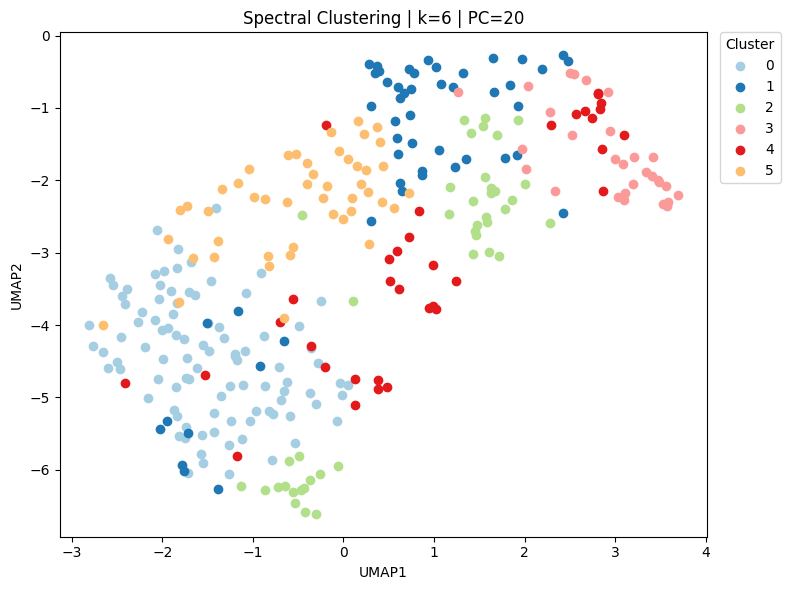

Silhouette score: 0.15747


In [57]:
# PCA on trajectory × (gene*timepoints) matrix
hdata.compute_PCA(
    data=subset_traj_,
    key="new_rna",                  # Use New RNA
    kind="trajectory",              # Use trajectory
    n_pc=20,
    trajectory_id=top_traj,
    id="new20_t"
)

# Compute distance/similarity in PC space
hdata.compute_similarity(
    data=subset_traj_,
    key="pca_trajectory_new20_t",       # "pca_trajectory_<your set id in .compute_PCA>"
    kind="trajectory",
    trajectory_id=top_traj,
    method="correlation",
    id="sim6"
)
sim6 = hdata.similarities["sim6"]

# Cluster in PC space
hdata.cluster_spectral(
        sim=sim6,                                               
        kind="trajectory",
        k=6,
        id="cl6"
    )
cl6 = hdata.clusters["cl6"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_traj_,
    key="pca_trajectory_new20_t",        # "pca_trajectory_<your set id in .compute_PCA>"
    kind="trajectory",
    trajectory_id=top_traj,
    id="em6"
)
em6 = hdata.embeddings["em6"]

# Visualize 
hda.visualize.scatter(
    cluster=cl6,
    embedding=em6,
    title="Spectral Clustering | k=6 | PC=20",
    show_label=False
)

# Evaluate
score6 = hdata.calc_cl_silhouette_score(
        cl=cl6, 
        precomputed=True, 
        sim=sim6
        )

print(f'Silhouette score: {score6:.5f}')

<a id="workflow22"></a>
#### Workflow 2.2 PCA first -> Concatenate

**cell $\times$ gene matrix → PCA → cell $\times$ PC matrix → build trajectory vectors using PC scores → trajectory $\times$ PC*timepoints matrix → distance/similarity matrix → clustering**

PCA matrix cell x 20 PCs stored in HDAData.layers["pca_cell_new20_c"] 

Similarity "sim7" stored! 

Cluster "cl7" stored! 

UMAP embedding "em7" stored! 



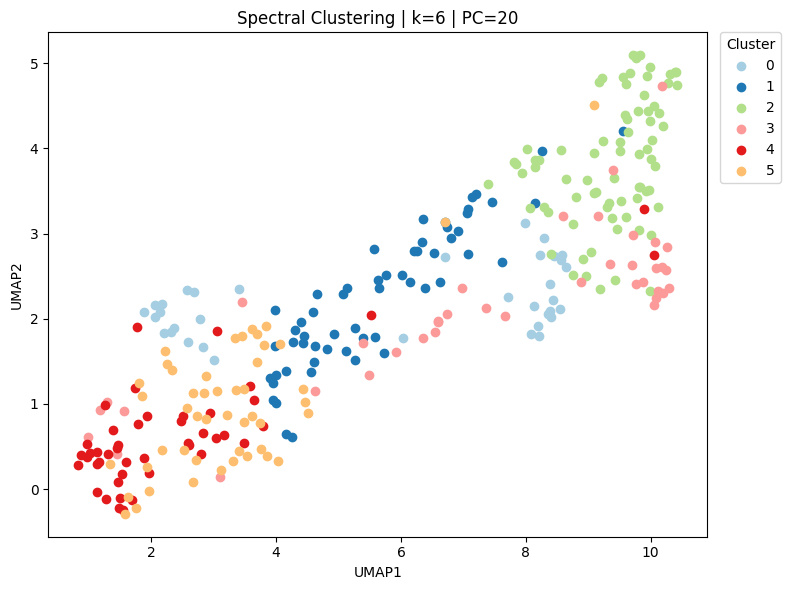

Silhouette score: 0.10509


In [58]:
# PCA on cell x PC matrix
hdata.compute_PCA(
    data=subset_traj_,
    key="new_rna",                  # use New RNA
    kind="cell",                    # use cell
    n_pc=20,
    id="new20_c"
)

# Compute distance/similarity in PC space
hdata.compute_similarity(
    data=subset_traj_,
    key="pca_cell_new20_c",        # "pca_cell_<your set id in .compute_PCA>"
    kind="trajectory",             
    trajectory_id=top_traj,
    method="correlation",
    id="sim7"
)
sim7 = hdata.similarities["sim7"]

# Cluster in PC space
hdata.cluster_spectral(
    sim=sim7,
    kind="trajectory",
    k=6,
    id="cl7"
)
cl7 = hdata.clusters["cl7"]

# Get UMAP embeddings
hdata.reduce_UMAP(
    data=subset_traj_,
    key="pca_cell_new20_c",      # "pca_cell_<your set id in .compute_PCA>"
    kind="trajectory",
    trajectory_id=top_traj,
    id="em7"
)
em7 = hdata.embeddings["em7"]

# Visualize 
hda.visualize.scatter(
    cluster=cl7,
    embedding=em7,
    title="Spectral Clustering | k=6 | PC=20",
    show_label=False
)

# Evaluate
score7 = hdata.calc_cl_silhouette_score(
        cl=cl7, 
        precomputed=True, 
        sim=sim7
        )

print(f'Silhouette score: {score7:.5f}')

For a quick comparison, the figure below shows clustering results for Total RNA vs. New RNA for trajectories using the two different workflows.

![img2ab](tutorial_images/img2ab.jpg)

<br>

---

That's it! Well done on reaching the end of the tutorial! 